# NIST TN 1822 — Verif.2.8: Horizontal counter-flows

100 agents move from room 1 to room 2 along a 10 m x 2 m corridor. A counterflow population of 0, 10, 50, 100 agents moves the other way. The time the last room-1 agent enters room 2 should increase with counterflow.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 11:01 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
from scenario_builders.nist2_8_counterflow import load_branches

## Run each branch

Room 2 begins at x = 20 m, so a room-1 agent enters it at its first frame with x >= 20. For each counterflow level we record the time the *last* room-1 agent enters room 2. If any room-1 agent never enters room 2 within the budget, the level is blocked and the time is unbounded; the NIST protocol asks for such blocking to be documented. One 400 s budget is used for every branch; the unblocked levels finish by about 70 s.

In [5]:
MAX_TIME = 400
ROOM2_X = 20.0

results = []
for branch in load_branches():
    scenario = load_scenario(str(branch.scenario_zip))
    scenario.max_simulation_time = MAX_TIME
    r = run_scenario(scenario, seed=42)
    df = r.trajectory_dataframe().sort_values(['id', 'frame'])
    first_x = df.groupby('id').first().x
    primary = first_x[first_x < 5.0].index
    entered = df[df.id.isin(primary) & (df.x >= ROOM2_X)].groupby('id').frame.min()
    completed = len(entered) == len(primary)
    results.append({'counterflow': branch.counterflow_agents, 'primary': len(primary), 'entered_room2': len(entered),
                    'completed': completed,
                    'last_entry_s': float(entered.max() / r.frame_rate) if completed else float('nan')})
    r.cleanup()
transit = pd.DataFrame(results)
for row in transit.itertuples():
    shown = f'{row.last_entry_s:.1f} s' if row.completed else 'blocking documented'
    print(f'counterflow={row.counterflow:>3}: {row.entered_room2:>3}/{row.primary} entered room 2, last entry: {shown}')
transit

counterflow=  0: 100/100 entered room 2, last entry: 46.6 s
counterflow= 10: 100/100 entered room 2, last entry: 70.0 s
counterflow= 50:   1/100 entered room 2, last entry: blocking documented
counterflow=100:   0/100 entered room 2, last entry: blocking documented


,counterflow,primary,entered_room2,completed,last_entry_s
0,0,100,100,True,46.6
1,10,100,100,True,70.0
2,50,100,1,False,NaN
3,100,100,0,False,NaN


## Plot last room-1 entry into room 2 vs counterflow

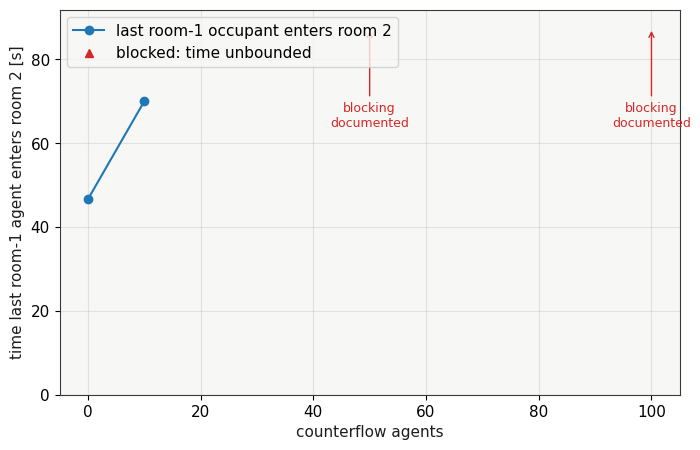

In [6]:
fig, ax = plt.subplots()
cf_levels = transit['counterflow'].to_numpy()
t_last = transit['last_entry_s'].to_numpy()
fin = transit['completed'].to_numpy(dtype=bool)
ax.plot(cf_levels[fin], t_last[fin], 'o-', color='tab:blue', label='last room-1 occupant enters room 2')
top = np.nanmax(t_last) * 1.25
for cf in cf_levels[~fin]:
    ax.annotate('blocking\ndocumented', xy=(cf, top), xytext=(cf, top * 0.8),
                ha='center', va='top', color='tab:red', fontsize=9,
                arrowprops=dict(arrowstyle='->', color='tab:red'))
ax.plot([], [], '^', color='tab:red', label='blocked: time unbounded')
ax.set_ylim(0, top * 1.05)
ax.set_xlim(-5, cf_levels.max() + 5)
ax.set_xlabel('counterflow agents')
ax.set_ylabel('time last room-1 agent enters room 2 [s]')
ax.legend(loc='upper left')
plt.show()

## Acceptance

NIST's stated trend is 'time for room-1 agents to enter room 2 increases as counterflow increases.' The metric is the time the last room-1 agent enters room 2. Rule: the 0-counterflow level must complete; levels where some room-1 agent never enters room 2 within the budget are reported as **blocking documented** (the time is unbounded and blocking is not counted as failure) and count as later than every finite level; the finite times must increase strictly with counterflow and no finite level may follow a blocked one.

In [7]:
completed = transit['completed'].to_numpy(dtype=bool)
counts = transit['counterflow'].tolist()
times = transit['last_entry_s'].to_numpy()
blocked = [c for c, ok in zip(counts, completed) if not ok]
finite = times[completed]
print('last room-1 entry into room 2 [s]:', dict(zip(counts, np.round(times, 1).tolist())))
print('blocking documented at counterflow level(s):', blocked)
# The 0-counterflow level must complete, otherwise the check below is vacuous.
assert completed[0], transit
# A blocked level counts as later than every finite level: no finite level may follow one.
assert all(completed[: len(finite)]) and not any(completed[len(finite):]), transit
# Finite last-entry times increase strictly with counterflow.
assert (np.diff(finite) > 0).all(), transit
print('RESULT: PASS - NIST TN 1822 Verif.2.8')

last room-1 entry into room 2 [s]: {0: 46.6, 10: 70.0, 50: nan, 100: nan}
blocking documented at counterflow level(s): [50, 100]
RESULT: PASS - NIST TN 1822 Verif.2.8
